In [172]:
import numpy as np
import matplotlib
import math
from matplotlib import axes
from matplotlib import tri
from matplotlib import pyplot
from matplotlib import patches as mplp
from matplotlib import lines as mlines
#from scipy.stats import kde
%matplotlib inline

In [173]:
# This is all of our observed data, cleaned up for our uses. 
MStar0Data=np.asarray(np.genfromtxt('ObservablePlus_FundamentalMStarData.csv',delimiter=',',skip_header=0))
MStar1Data=np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneMStarData.csv',delimiter=',',skip_header=0))
CStar0Data=np.asarray(np.genfromtxt('ObservablePlus_FundCStarData.csv',delimiter=',',skip_header=0))
CStar1Data=np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneCStarData.csv',delimiter=',',skip_header=0))

# From these files, these are the indices of the various observational parameters we'll be looking at here
TotalMdotIndex=5
TotalMdotErrorIndex=6
LBolIndex = 8
LBol_errorIndex = 9
TeffIndex=12
PeriodIndex=13
magJIndex=14
magHIndex=15
magKIndex=16
mag36Index=17
mag45Index=18
mag58Index=19
mag80Index=20
MassIndex=22
RadiusIndex=23
CalculatedTeffIndex=24

In [174]:
# We want to clean the set a bit more. This function does some additional removal of strange sources.
def ErrorClean_2 (Data_Set): # A function to clear all data with unreliable values in Mdot or L, as done by Lee Anne
    # 39 stars with logLerror = 0 ---------- Cut if logL error = 0
    # 13 remaining with logL>4.5, then ------------ Cut if logL>4.5
    # 22 with M<0.45 --------------- Cut if M<0.45
    CuttingArray = []
    i = 0
    Cleaned_Set = np.transpose(Data_Set)
    # First, deltalogL = 0 or deltalogL is nAn
    while i<len(Data_Set[LBol_errorIndex]):
        if Data_Set[LBol_errorIndex][i] == 0: # If the ith entry's error is zero
            CuttingArray.append(i)
            #print('Star cut because delta_logL is 0')
        elif np.isnan(Data_Set[LBol_errorIndex][i]) == True: # If the ith entry's error is nAn
            CuttingArray.append(i)
            #print('Star cut because delta_logL is nan')
        i += 1
    # Second, issues with logL
    i = 0
    while i<len(Data_Set[LBolIndex]):
        if np.log10(Data_Set[LBolIndex][i]) >= 4.5: # If the ith entry's luminosity is more than 10^4.5
            CuttingArray.append(i)
            #print('Star cut because logL>4.5')
        i += 1
    # Now issues with M
    i = 0
    while i<len(Data_Set[MassIndex]):
        if Data_Set[MassIndex][i] < 0.45: # If the ith entry's mass is less than 0.45
            CuttingArray.append(i)
            #print('Star cut because M<0.45')
        i += 1
    CuttingArray = np.unique(CuttingArray)
    Cleaned_Set = np.delete(Cleaned_Set,CuttingArray,axis=0)
    print ('Entries Removed:',len(CuttingArray))
    print ('Stars Remaining:', len(Cleaned_Set))
    return np.transpose(Cleaned_Set)
        

In [175]:
MStar0Data=ErrorClean_2(np.transpose(MStar0Data))

Entries Removed: 107
Stars Remaining: 1951


In [176]:
MStar1Data=ErrorClean_2(np.transpose(MStar1Data))

Entries Removed: 74
Stars Remaining: 2161


In [177]:
CStar0Data=ErrorClean_2(np.transpose(CStar0Data))

Entries Removed: 70
Stars Remaining: 1994


In [178]:
CStar1Data=ErrorClean_2(np.transpose(CStar1Data))

Entries Removed: 53
Stars Remaining: 781


# M Fundamental Stars

## From these files, these are the indices of the various observational parameters we'll be looking at here
### TotalMdotIndex=5
### TotalMdotErrorIndex=6
### LBolIndex = 8
### LBol_errorIndex = 9
### TeffIndex=12
### PeriodIndex=13
### magJIndex=14
### magHIndex=15
### magKIndex=16
### mag36Index=17
### mag45Index=18
### mag58Index=19
### mag80Index=20
### MassIndex=22
### RadiusIndex=23
### CalculatedTeffIndex=24

Ks vs J-Ks

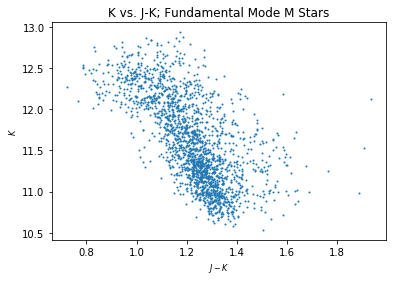

In [179]:
X = MStar0Data[magJIndex]-MStar0Data[magKIndex]
Y = MStar0Data[magKIndex]

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$J-K$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$K$')
PylabelText.set_fontsize(8) 
pyplot.title('K vs. J-K; Fundamental Mode M Stars')

pyplot.plot(X,Y,linestyle='',ms=2,marker='.')

[8.0] vs. J-[8.0]

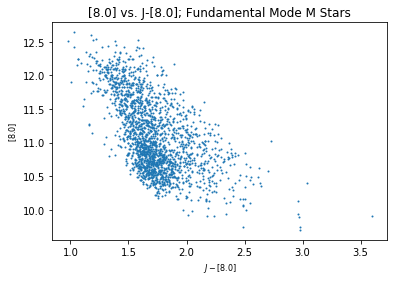

In [180]:
X = MStar0Data[magJIndex]-MStar0Data[mag80Index]
Y = MStar0Data[mag80Index]

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$J-[8.0]$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[8.0]$')
PylabelText.set_fontsize(8) 
pyplot.title('[8.0] vs. J-[8.0]; Fundamental Mode M Stars')

pyplot.plot(X,Y,linestyle='',ms=2,marker='.')

[4.5] vs. J-[4.5]

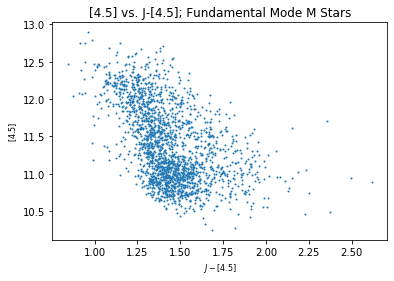

In [181]:
X = MStar0Data[magJIndex]-MStar0Data[mag45Index]
Y = MStar0Data[mag45Index]

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$J-[4.5]$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[4.5]$')
PylabelText.set_fontsize(8) 
pyplot.title('[4.5] vs. J-[4.5]; Fundamental Mode M Stars')

pyplot.plot(X,Y,linestyle='',ms=2,marker='.')

[8.0] vs. [3.6]-[8.0]

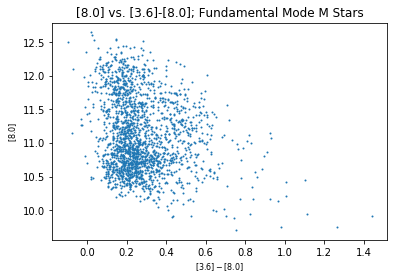

In [182]:
X = MStar0Data[mag36Index]-MStar0Data[mag80Index]
Y = MStar0Data[mag80Index]

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$[3.6]-[8.0]$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[8.0]$')
PylabelText.set_fontsize(8) 
pyplot.title('[8.0] vs. [3.6]-[8.0]; Fundamental Mode M Stars')

pyplot.plot(X,Y,linestyle='',ms=2,marker='.')

[3.6] vs. [3.6]-[8.0]

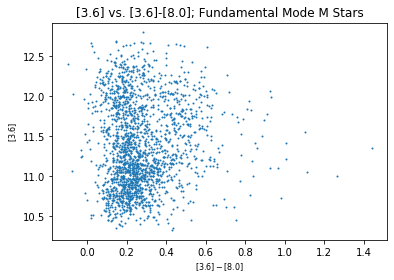

In [183]:
X = MStar0Data[mag36Index]-MStar0Data[mag80Index]
Y = MStar0Data[mag36Index]

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$[3.6]-[8.0]$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[3.6]$')
PylabelText.set_fontsize(8) 
pyplot.title('[3.6] vs. [3.6]-[8.0]; Fundamental Mode M Stars')

pyplot.plot(X,Y,linestyle='',ms=2,marker='.')

[3.6]-[4.5] vs. [5.8]-[8.0]

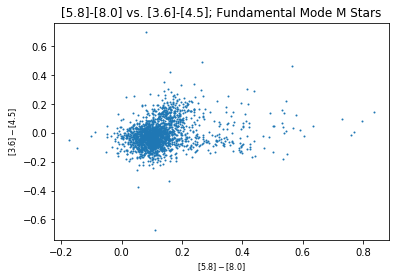

In [184]:
X = MStar0Data[mag58Index]-MStar0Data[mag80Index]
Y = MStar0Data[mag36Index]-MStar0Data[mag45Index]

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$[5.8]-[8.0]$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[3.6]-[4.5]$')
PylabelText.set_fontsize(8) 
pyplot.title('[5.8]-[8.0] vs. [3.6]-[4.5]; Fundamental Mode M Stars')

pyplot.plot(X,Y,linestyle='',ms=2,marker='.')

[3.6]-[8.0] vs. J-Ks

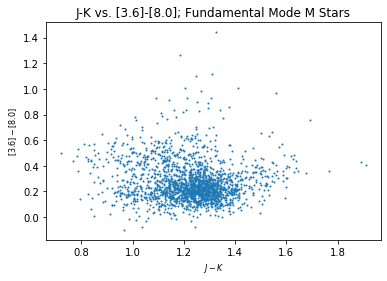

In [185]:
X = MStar0Data[magJIndex]-MStar0Data[magKIndex]
Y = MStar0Data[mag36Index]-MStar0Data[mag80Index]

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$J-K$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[3.6]-[8.0]$')
PylabelText.set_fontsize(8) 
pyplot.title('J-K vs. [3.6]-[8.0]; Fundamental Mode M Stars')

pyplot.plot(X,Y,linestyle='',ms=2,marker='.')

# M Overtone Stars

In [186]:
# Next, we need to sort out stars in suspect regions. There may be overlap here, so we should have multiple sets.

def sort_suspect_Mass_MOvertones (Data_Set):
    SortingArray = []
    i = 0
    # First, deltalogL = 0 or deltalogL is nAn
    while i<len(Data_Set[MassIndex]):
        if np.log10(Data_Set[MassIndex][i]) >= 0.35: # If the ith entry's error is zero
            SortingArray.append(i)
            #print('Star marked because logM>=0.35 is 0')
        i += 1
    SortingArray = np.unique(SortingArray)
    Sorted_Set = np.transpose(Data_Set)[SortingArray]
    print ('Entries Marked:',len(SortingArray))
    return np.transpose(Sorted_Set)



In [187]:
Suspect_MOvertones=sort_suspect_Mass_MOvertones(MStar1Data)

Entries Marked: 64


Ks vs J-Ks

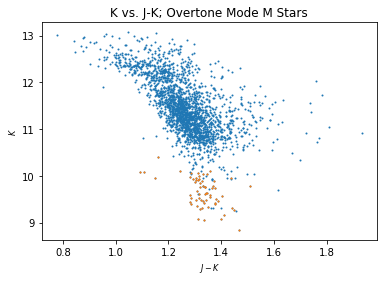

In [188]:
X = MStar1Data[magJIndex]-MStar1Data[magKIndex]
Y = MStar1Data[magKIndex]
SuspectX = Suspect_MOvertones[magJIndex]-Suspect_MOvertones[magKIndex]
SuspectY = Suspect_MOvertones[magKIndex]

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$J-K$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$K$')
PylabelText.set_fontsize(8) 
pyplot.title('K vs. J-K; Overtone Mode M Stars')

pyplot.plot(X,Y,linestyle='',ms=2,marker='.')
pyplot.plot(SuspectX,SuspectY,linestyle='',ms=2,marker='.')

[8.0] vs. J-[8.0]

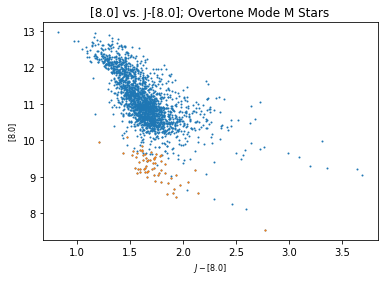

In [189]:
X = MStar1Data[magJIndex]-MStar1Data[mag80Index]
Y = MStar1Data[mag80Index]
SuspectX = Suspect_MOvertones[magJIndex]-Suspect_MOvertones[mag80Index]
SuspectY = Suspect_MOvertones[mag80Index]

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$J-[8.0]$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[8.0]$')
PylabelText.set_fontsize(8) 
pyplot.title('[8.0] vs. J-[8.0]; Overtone Mode M Stars')

pyplot.plot(X,Y,linestyle='',ms=2,marker='.')
pyplot.plot(SuspectX,SuspectY,linestyle='',ms=2,marker='.')

[4.5] vs. J-[4.5]

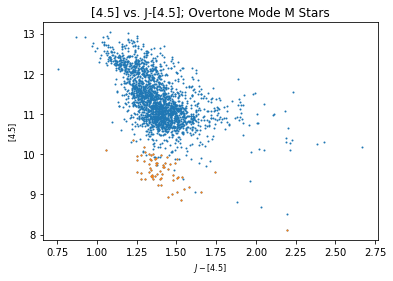

In [190]:
X = MStar1Data[magJIndex]-MStar1Data[mag45Index]
Y = MStar1Data[mag45Index]
SuspectX = Suspect_MOvertones[magJIndex]-Suspect_MOvertones[mag45Index]
SuspectY = Suspect_MOvertones[mag45Index]

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$J-[4.5]$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[4.5]$')
PylabelText.set_fontsize(8) 
pyplot.title('[4.5] vs. J-[4.5]; Overtone Mode M Stars')

pyplot.plot(X,Y,linestyle='',ms=2,marker='.')
pyplot.plot(SuspectX,SuspectY,linestyle='',ms=2,marker='.')

[8.0] vs. [3.6]-[8.0]

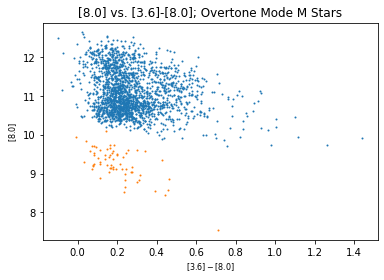

In [191]:
X = MStar0Data[mag36Index]-MStar0Data[mag80Index]
Y = MStar0Data[mag80Index]
SuspectX = Suspect_MOvertones[mag36Index]-Suspect_MOvertones[mag80Index]
SuspectY = Suspect_MOvertones[mag80Index]

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$[3.6]-[8.0]$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[8.0]$')
PylabelText.set_fontsize(8) 
pyplot.title('[8.0] vs. [3.6]-[8.0]; Overtone Mode M Stars')

pyplot.plot(X,Y,linestyle='',ms=2,marker='.')
pyplot.plot(SuspectX,SuspectY,linestyle='',ms=2,marker='.')

[3.6] vs. [3.6]-[8.0]

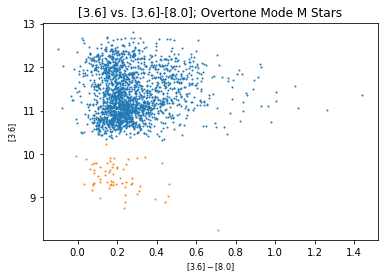

In [192]:
X = MStar0Data[mag36Index]-MStar0Data[mag80Index]
Y = MStar0Data[mag36Index]
SuspectX = Suspect_MOvertones[mag36Index]-Suspect_MOvertones[mag80Index]
SuspectY = Suspect_MOvertones[mag36Index]

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$[3.6]-[8.0]$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[3.6]$')
PylabelText.set_fontsize(8) 
pyplot.title('[3.6] vs. [3.6]-[8.0]; Overtone Mode M Stars')

pyplot.plot(X,Y,linestyle='',ms=2,marker='.')
pyplot.plot(SuspectX,SuspectY,linestyle='',ms=2,marker='.')

[3.6]-[4.5] vs. [5.8]-[8.0]

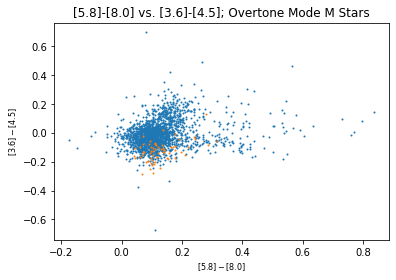

In [193]:
X = MStar0Data[mag58Index]-MStar0Data[mag80Index]
Y = MStar0Data[mag36Index]-MStar0Data[mag45Index]
SuspectX = Suspect_MOvertones[mag58Index]-Suspect_MOvertones[mag80Index]
SuspectY = Suspect_MOvertones[mag36Index]-Suspect_MOvertones[mag45Index]

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$[5.8]-[8.0]$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[3.6]-[4.5]$')
PylabelText.set_fontsize(8) 
pyplot.title('[5.8]-[8.0] vs. [3.6]-[4.5]; Overtone Mode M Stars')

pyplot.plot(X,Y,linestyle='',ms=2,marker='.')
pyplot.plot(SuspectX,SuspectY,linestyle='',ms=2,marker='.')

[3.6]-[8.0] vs. J-Ks

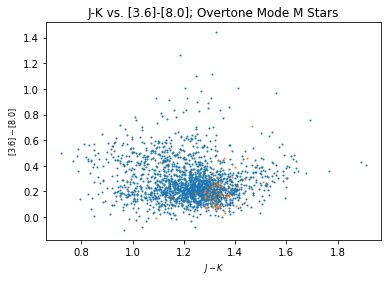

In [194]:
X = MStar0Data[magJIndex]-MStar0Data[magKIndex]
Y = MStar0Data[mag36Index]-MStar0Data[mag80Index]
SuspectX = Suspect_MOvertones[magJIndex]-Suspect_MOvertones[magKIndex]
SuspectY = Suspect_MOvertones[mag36Index]-Suspect_MOvertones[mag80Index]

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$J-K$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[3.6]-[8.0]$')
PylabelText.set_fontsize(8) 
pyplot.title('J-K vs. [3.6]-[8.0]; Overtone Mode M Stars')

pyplot.plot(X,Y,linestyle='',ms=2,marker='.')
pyplot.plot(SuspectX,SuspectY,linestyle='',ms=2,marker='.')

# C Fundamental Stars

In [195]:
# Next, we need to sort out stars in suspect regions. There may be overlap here, so we should have multiple sets.

def sort_suspect_Mdots_CFunds (Data_Set):
    SortingArray = []
    i = 0
    # First, deltalogL = 0 or deltalogL is nAn
    while i<len(Data_Set[TotalMdotIndex]):
        if np.log10(Data_Set[TotalMdotIndex][i]/(2.7*10**-7)) >= 0.8 and np.log10(Data_Set[TotalMdotIndex][i]/(2.7*10**-7)) <=1.2: # If the ith entry's mass loss rate is near critical
            SortingArray.append(i)
            #print('Star marked because logM>=0.35 is 0')
        i += 1
    SortingArray = np.unique(SortingArray)
    Sorted_Set = np.transpose(Data_Set)[SortingArray]
    print ('Entries Marked:',len(SortingArray))
    return np.transpose(Sorted_Set)



In [196]:
Suspect_CFunds=sort_suspect_Mdots_CFunds(CStar0Data)

Entries Marked: 140


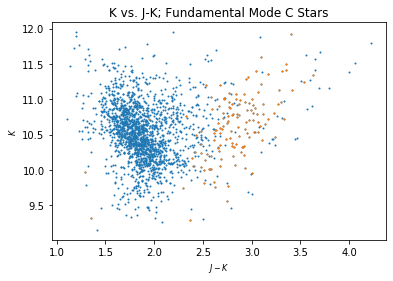

In [197]:
X = CStar0Data[magJIndex]-CStar0Data[magKIndex]
Y = CStar0Data[magKIndex]
SuspectX = Suspect_CFunds[magJIndex]-Suspect_CFunds[magKIndex]
SuspectY = Suspect_CFunds[magKIndex]

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$J-K$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$K$')
PylabelText.set_fontsize(8) 
pyplot.title('K vs. J-K; Fundamental Mode C Stars')

pyplot.plot(X,Y,linestyle='',ms=2,marker='.')
pyplot.plot(SuspectX,SuspectY,linestyle='',ms=2,marker='.')

[8.0] vs. J-[8.0]

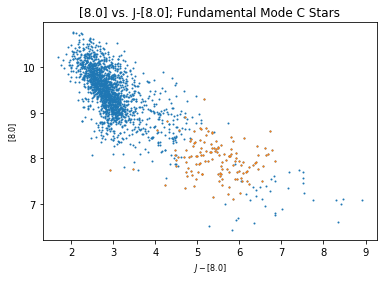

In [198]:
X = CStar0Data[magJIndex]-CStar0Data[mag80Index]
Y = CStar0Data[mag80Index]
SuspectX = Suspect_CFunds[magJIndex]-Suspect_CFunds[mag80Index]
SuspectY = Suspect_CFunds[mag80Index]

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$J-[8.0]$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[8.0]$')
PylabelText.set_fontsize(8) 
pyplot.title('[8.0] vs. J-[8.0]; Fundamental Mode C Stars')

pyplot.plot(X,Y,linestyle='',ms=2,marker='.')
pyplot.plot(SuspectX,SuspectY,linestyle='',ms=2,marker='.')

[4.5] vs. J-[4.5]

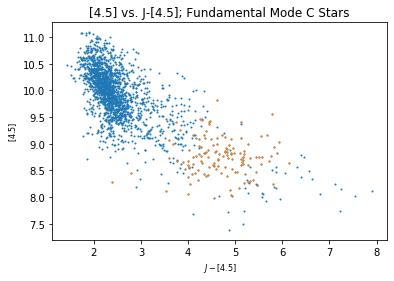

In [199]:
X = CStar0Data[magJIndex]-CStar0Data[mag45Index]
Y = CStar0Data[mag45Index]
SuspectX = Suspect_CFunds[magJIndex]-Suspect_CFunds[mag45Index]
SuspectY = Suspect_CFunds[mag45Index]

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$J-[4.5]$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[4.5]$')
PylabelText.set_fontsize(8) 
pyplot.title('[4.5] vs. J-[4.5]; Fundamental Mode C Stars')

pyplot.plot(X,Y,linestyle='',ms=2,marker='.')
pyplot.plot(SuspectX,SuspectY,linestyle='',ms=2,marker='.')

[8.0] vs. [3.6]-[8.0]

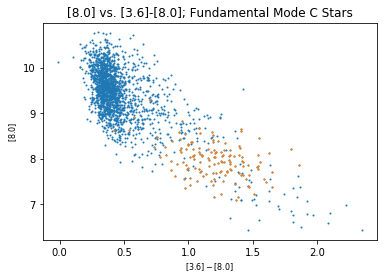

In [200]:
X = CStar0Data[mag36Index]-CStar0Data[mag80Index]
Y = CStar0Data[mag80Index]
SuspectX = Suspect_CFunds[mag36Index]-Suspect_CFunds[mag80Index]
SuspectY = Suspect_CFunds[mag80Index]

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$[3.6]-[8.0]$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[8.0]$')
PylabelText.set_fontsize(8) 
pyplot.title('[8.0] vs. [3.6]-[8.0]; Fundamental Mode C Stars')

pyplot.plot(X,Y,linestyle='',ms=2,marker='.')
pyplot.plot(SuspectX,SuspectY,linestyle='',ms=2,marker='.')

[3.6] vs. [3.6]-[8.0]

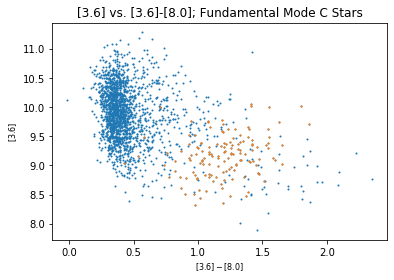

In [201]:
X = CStar0Data[mag36Index]-CStar0Data[mag80Index]
Y = CStar0Data[mag36Index]
SuspectX = Suspect_CFunds[mag36Index]-Suspect_CFunds[mag80Index]
SuspectY = Suspect_CFunds[mag36Index]

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$[3.6]-[8.0]$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[3.6]$')
PylabelText.set_fontsize(8) 
pyplot.title('[3.6] vs. [3.6]-[8.0]; Fundamental Mode C Stars')

pyplot.plot(X,Y,linestyle='',ms=2,marker='.')
pyplot.plot(SuspectX,SuspectY,linestyle='',ms=2,marker='.')

[3.6]-[4.5] vs. [5.8]-[8.0]

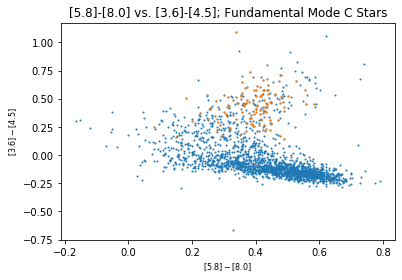

In [202]:
X = CStar0Data[mag58Index]-CStar0Data[mag80Index]
Y = CStar0Data[mag36Index]-CStar0Data[mag45Index]
SuspectX = Suspect_CFunds[mag58Index]-Suspect_CFunds[mag80Index]
SuspectY = Suspect_CFunds[mag36Index]-Suspect_CFunds[mag45Index]

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$[5.8]-[8.0]$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[3.6]-[4.5]$')
PylabelText.set_fontsize(8) 
pyplot.title('[5.8]-[8.0] vs. [3.6]-[4.5]; Fundamental Mode C Stars')

pyplot.plot(X,Y,linestyle='',ms=2,marker='.')
pyplot.plot(SuspectX,SuspectY,linestyle='',ms=2,marker='.')

[3.6]-[8.0] vs. J-Ks

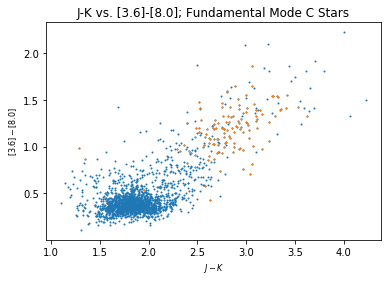

In [203]:
X = CStar0Data[magJIndex]-CStar0Data[magKIndex]
Y = CStar0Data[mag36Index]-CStar0Data[mag80Index]
SuspectX = Suspect_CFunds[magJIndex]-Suspect_CFunds[magKIndex]
SuspectY = Suspect_CFunds[mag36Index]-Suspect_CFunds[mag80Index]

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$J-K$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[3.6]-[8.0]$')
PylabelText.set_fontsize(8) 
pyplot.title('J-K vs. [3.6]-[8.0]; Fundamental Mode C Stars')

pyplot.plot(X,Y,linestyle='',ms=2,marker='.')
pyplot.plot(SuspectX,SuspectY,linestyle='',ms=2,marker='.')

# C Overtone Stars

Ks vs J-Ks

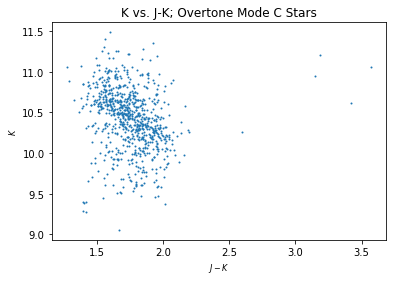

In [204]:
X = CStar1Data[magJIndex]-CStar1Data[magKIndex]
Y = CStar1Data[magKIndex]

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$J-K$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$K$')
PylabelText.set_fontsize(8) 
pyplot.title('K vs. J-K; Overtone Mode C Stars')

pyplot.plot(X,Y,linestyle='',ms=2,marker='.')

[8.0] vs. J-[8.0]

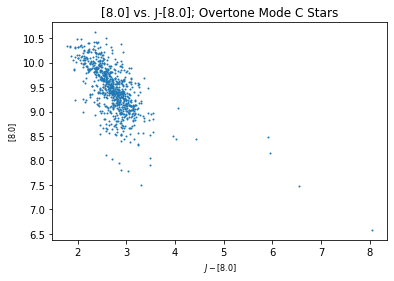

In [205]:
X = CStar1Data[magJIndex]-CStar1Data[mag80Index]
Y = CStar1Data[mag80Index]

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$J-[8.0]$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[8.0]$')
PylabelText.set_fontsize(8) 
pyplot.title('[8.0] vs. J-[8.0]; Overtone Mode C Stars')

pyplot.plot(X,Y,linestyle='',ms=2,marker='.')

[4.5] vs. J-[4.5]

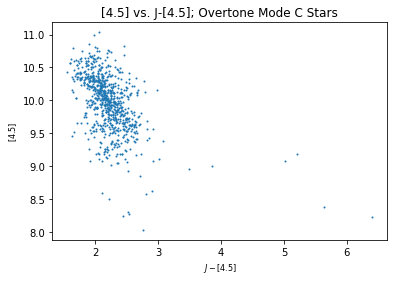

In [206]:
X = CStar1Data[magJIndex]-CStar1Data[mag45Index]
Y = CStar1Data[mag45Index]

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$J-[4.5]$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[4.5]$')
PylabelText.set_fontsize(8) 
pyplot.title('[4.5] vs. J-[4.5]; Overtone Mode C Stars')

pyplot.plot(X,Y,linestyle='',ms=2,marker='.')

[8.0] vs. [3.6]-[8.0]

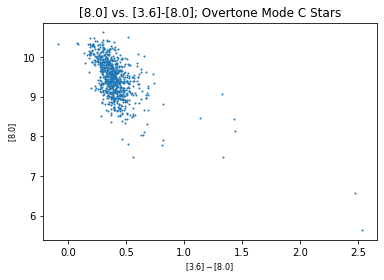

In [207]:
X = CStar1Data[mag36Index]-CStar1Data[mag80Index]
Y = CStar1Data[mag80Index]

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$[3.6]-[8.0]$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[8.0]$')
PylabelText.set_fontsize(8) 
pyplot.title('[8.0] vs. [3.6]-[8.0]; Overtone Mode C Stars')

pyplot.plot(X,Y,linestyle='',ms=2,marker='.')

[3.6] vs. [3.6]-[8.0]

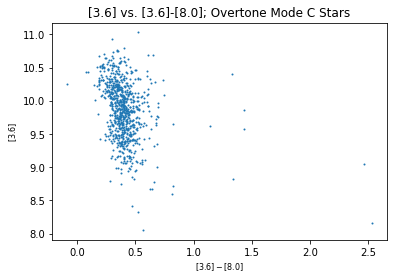

In [208]:
X = CStar1Data[mag36Index]-CStar1Data[mag80Index]
Y = CStar1Data[mag36Index]

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$[3.6]-[8.0]$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[3.6]$')
PylabelText.set_fontsize(8) 
pyplot.title('[3.6] vs. [3.6]-[8.0]; Overtone Mode C Stars')

pyplot.plot(X,Y,linestyle='',ms=2,marker='.')

[3.6]-[4.5] vs. [5.8]-[8.0]

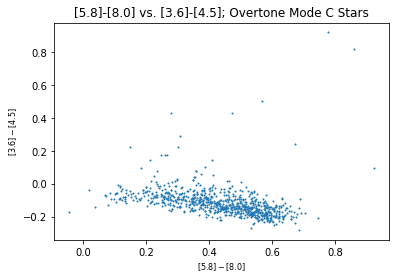

In [209]:
X = CStar1Data[mag58Index]-CStar1Data[mag80Index]
Y = CStar1Data[mag36Index]-CStar1Data[mag45Index]

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$[5.8]-[8.0]$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[3.6]-[4.5]$')
PylabelText.set_fontsize(8) 
pyplot.title('[5.8]-[8.0] vs. [3.6]-[4.5]; Overtone Mode C Stars')

pyplot.plot(X,Y,linestyle='',ms=2,marker='.')

[3.6]-[8.0] vs. J-Ks

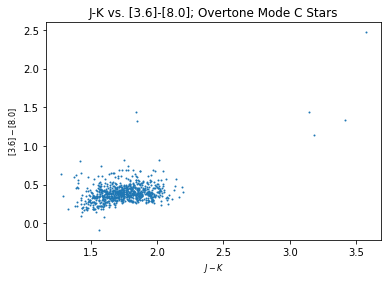

In [210]:
X = CStar1Data[magJIndex]-CStar1Data[magKIndex]
Y = CStar1Data[mag36Index]-CStar1Data[mag80Index]

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$J-K$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[3.6]-[8.0]$')
PylabelText.set_fontsize(8) 
pyplot.title('J-K vs. [3.6]-[8.0]; Overtone Mode C Stars')

pyplot.plot(X,Y,linestyle='',ms=2,marker='.')